# Chapter 12: Cross-Validation and Model Evaluation Techniques

This notebook covers Chapter 12 of *scikit-learn Cookbook* (3rd Edition, Packt). A model is only useful if it performs well on **new, unseen data**. This chapter covers how to estimate that performance reliably, choose the right metric, tune hyperparameters without fooling ourselves, and diagnose overfitting and underfitting.

**Topics covered:**
- The holdout method and its limitations
- K-Fold, Stratified K-Fold, and other cross-validation splitters
- Group-aware and time-series cross-validation
- `cross_val_score`, `cross_validate`, and `cross_val_predict`
- Choosing metrics and building custom scorers
- Baselines with dummy models
- Hyperparameter search: grid, randomized, and successive halving
- Nested cross-validation
- Learning curves and validation curves

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

from sklearn.datasets import load_breast_cancer, load_diabetes, make_classification
from sklearn.model_selection import (train_test_split, KFold, StratifiedKFold, GroupKFold,
                                     TimeSeriesSplit, ShuffleSplit, LeaveOneOut,
                                     cross_val_score, cross_validate, cross_val_predict,
                                     GridSearchCV, RandomizedSearchCV,
                                     LearningCurveDisplay, ValidationCurveDisplay)
from sklearn.experimental import enable_halving_search_cv  # noqa: F401
from sklearn.model_selection import HalvingGridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline, Pipeline
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.metrics import (make_scorer, fbeta_score, confusion_matrix,
                             classification_report)
from scipy.stats import loguniform

cancer = load_breast_cancer()
X, y = cancer.data, cancer.target
model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))

## 1. The Holdout Method and Its Limitations

The simplest evaluation splits the data once into a training set and a test set. It is fast, but the result depends on **which** samples happened to land in the test set. With small datasets, different random splits can give noticeably different scores.

In [2]:
scores = []
for seed in range(20):
    X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, random_state=seed)
    scores.append(model.fit(X_tr, y_tr).score(X_te, y_te))

print(f'Holdout accuracy over 20 random splits: min = {min(scores):.3f}, '
      f'max = {max(scores):.3f}, std = {np.std(scores):.3f}')

Holdout accuracy over 20 random splits: min = 0.947, max = 0.991, std = 0.011


The same model gets different accuracies depending only on the random split. A single holdout score is therefore an uncertain estimate. Cross-validation reduces this uncertainty by using every sample for testing exactly once.

## 2. K-Fold Cross-Validation

In **K-Fold cross-validation**, the data is split into $K$ folds. The model is trained $K$ times, each time on $K-1$ folds and tested on the remaining fold. The final estimate is the mean of the $K$ scores, and their standard deviation shows how stable the model is:

$$\text{CV score} = \frac{1}{K}\sum_{k=1}^{K} \text{score}_k$$

- **KFold**: plain splits (use `shuffle=True` if the data is ordered).
- **StratifiedKFold**: keeps the class proportions the same in every fold, which is the default for classifiers and important for imbalanced data.
- **ShuffleSplit**: repeated random train/test splits.
- **LeaveOneOut**: $K = n$; almost no bias, but very expensive and high variance.

In [3]:
splitters = {
    'KFold (5)': KFold(n_splits=5, shuffle=True, random_state=42),
    'StratifiedKFold (5)': StratifiedKFold(n_splits=5, shuffle=True, random_state=42),
    'ShuffleSplit (10 x 20%)': ShuffleSplit(n_splits=10, test_size=0.2, random_state=42),
}
for name, cv in splitters.items():
    s = cross_val_score(model, X, y, cv=cv)
    print(f'{name:>24}: mean = {s.mean():.3f}, std = {s.std():.3f}')

print('\nClass share of malignant tumors in each StratifiedKFold test fold:')
for _, test_idx in StratifiedKFold(5, shuffle=True, random_state=42).split(X, y):
    print(f'  {np.mean(y[test_idx] == 0):.3f}', end='')
print(f'\nOverall share: {np.mean(y == 0):.3f}')

               KFold (5): mean = 0.977, std = 0.009
     StratifiedKFold (5): mean = 0.974, std = 0.017
 ShuffleSplit (10 x 20%): mean = 0.982, std = 0.012

Class share of malignant tumors in each StratifiedKFold test fold:
  0.377  0.377  0.368  0.368  0.372
Overall share: 0.373


In [4]:
X_small, y_small = X[:100], y[:100]
start = time.perf_counter()
loo = cross_val_score(model, X_small, y_small, cv=LeaveOneOut())
print(f'LeaveOneOut on 100 samples: {len(loo)} fits, mean accuracy = {loo.mean():.3f}, '
      f'time = {time.perf_counter() - start:.1f} s')

LeaveOneOut on 100 samples: 100 fits, mean accuracy = 0.920, time = 1.0 s


All splitters give similar mean accuracy, but cross-validation also reports the spread. Stratified folds keep the share of malignant tumors almost identical to the full dataset in every fold. Leave-One-Out needs one fit per sample, which is why it is only practical for small datasets.

## 3. Group-Aware and Time-Series Splits

Standard CV assumes samples are **independent**. Two common situations break this assumption:
- **Groups**: several samples come from the same patient, customer, or device. If the same group appears in both training and test folds, the score is too optimistic. `GroupKFold` keeps each group entirely in one fold.
- **Time series**: future data must never be used to predict the past. `TimeSeriesSplit` always trains on earlier data and tests on the period right after it.

In [5]:
X_g, y_g = make_classification(n_samples=200, n_features=5, random_state=0)
groups = np.repeat(np.arange(20), 10)   # 20 patients, 10 measurements each

for train_idx, test_idx in GroupKFold(n_splits=4).split(X_g, y_g, groups):
    overlap = set(groups[train_idx]) & set(groups[test_idx])
    print(f'test groups: {sorted(set(groups[test_idx]))}, overlap with train: {len(overlap)}')

test groups: [np.int64(3), np.int64(7), np.int64(11), np.int64(15), np.int64(19)], overlap with train: 0
test groups: [np.int64(2), np.int64(6), np.int64(10), np.int64(14), np.int64(18)], overlap with train: 0
test groups: [np.int64(1), np.int64(5), np.int64(9), np.int64(13), np.int64(17)], overlap with train: 0
test groups: [np.int64(0), np.int64(4), np.int64(8), np.int64(12), np.int64(16)], overlap with train: 0


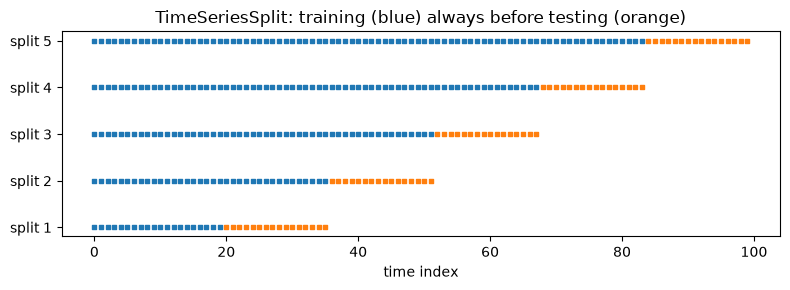

In [6]:
tscv = TimeSeriesSplit(n_splits=5)
fig, ax = plt.subplots(figsize=(8, 3))
for i, (tr, te) in enumerate(tscv.split(np.arange(100))):
    ax.scatter(tr, [i] * len(tr), c='tab:blue', marker='s', s=10)
    ax.scatter(te, [i] * len(te), c='tab:orange', marker='s', s=10)
ax.set_yticks(range(5))
ax.set_yticklabels([f'split {i + 1}' for i in range(5)])
ax.set_xlabel('time index')
ax.set_title('TimeSeriesSplit: training (blue) always before testing (orange)')
plt.tight_layout()
plt.show()

`GroupKFold` never puts the same patient in both training and test data, so the score reflects performance on **new** patients. In `TimeSeriesSplit`, the training window grows over time and each test period comes after its training data, matching how the model would be used in reality.

## 4. `cross_validate` and `cross_val_predict`

- `cross_val_score` returns one metric per fold.
- `cross_validate` can compute **several metrics** at once and also returns training scores and fit times, which helps detect overfitting.
- `cross_val_predict` returns an out-of-fold prediction for every sample, useful for building a confusion matrix or residual plots based on cross-validation.

In [7]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
res = cross_validate(model, X, y, cv=cv,
                     scoring=['accuracy', 'precision', 'recall', 'f1', 'roc_auc'],
                     return_train_score=True)

summary = pd.DataFrame(res).drop(columns=['fit_time', 'score_time']).agg(['mean', 'std']).T
summary.round(3)

,mean,std
test_accuracy,0.974,0.019
train_accuracy,0.988,0.001
test_precision,0.968,0.032
train_precision,0.986,0.003
test_recall,0.992,0.013
train_recall,0.995,0.002
test_f1,0.979,0.014
train_f1,0.991,0.001
test_roc_auc,0.995,0.006
train_roc_auc,0.998,0.001


In [8]:
y_oof = cross_val_predict(model, X, y, cv=cv)
print('Confusion matrix from out-of-fold predictions:')
print(confusion_matrix(y, y_oof))
print(classification_report(y, y_oof, target_names=cancer.target_names))

Confusion matrix from out-of-fold predictions:
[[200  12]
 [  3 354]]
              precision    recall  f1-score   support

   malignant       0.99      0.94      0.96       212
      benign       0.97      0.99      0.98       357

    accuracy                           0.97       569
   macro avg       0.98      0.97      0.97       569
weighted avg       0.97      0.97      0.97       569



Training and test scores are close for every metric, so the model is not overfitting. The out-of-fold confusion matrix uses predictions made only by models that never saw each sample, giving an honest picture of the errors across the whole dataset.

## 5. Choosing Metrics and Custom Scorers

The right metric depends on the problem:
- **Classification**: accuracy (balanced classes), precision (false positives are costly), recall (false negatives are costly), F1 (balance of both), ROC AUC (ranking quality).
- **Regression**: MAE (average absolute error), RMSE (penalizes large errors more), $R^2$ (share of variance explained).

In scikit-learn, every scorer follows "**higher is better**", so error metrics appear as negatives (e.g., `neg_mean_squared_error`). Custom metrics can be wrapped with `make_scorer`. For example, the **F2-score** weights recall more than precision:

$$F_\beta = (1 + \beta^2)\frac{\text{precision} \cdot \text{recall}}{\beta^2 \cdot \text{precision} + \text{recall}}$$

In [9]:
# Malignant (class 0) is the class we care about catching
f2_malignant = make_scorer(fbeta_score, beta=2, pos_label=0)
print(f'F2 (malignant) CV score: {cross_val_score(model, X, y, cv=cv, scoring=f2_malignant).mean():.3f}')

diab = load_diabetes()
reg = make_pipeline(StandardScaler(), Ridge(alpha=1.0))
reg_res = cross_validate(reg, diab.data, diab.target, cv=5,
                         scoring=['neg_mean_absolute_error', 'neg_root_mean_squared_error', 'r2'])
print(f'Ridge on diabetes: MAE = {-reg_res["test_neg_mean_absolute_error"].mean():.2f}, '
      f'RMSE = {-reg_res["test_neg_root_mean_squared_error"].mean():.2f}, '
      f'R2 = {reg_res["test_r2"].mean():.3f}')

F2 (malignant) CV score: 0.951
Ridge on diabetes: MAE = 44.26, RMSE = 54.70, R2 = 0.482


The custom F2 scorer focuses on catching malignant tumors, which matters more in medical screening than avoiding false alarms. For regression, the negative error scores are flipped back to positive numbers when reported.

## 6. Baselines with Dummy Models

A score means little without a reference. **Dummy models** give the performance of trivial strategies, such as always predicting the most frequent class or the mean target value. A real model must clearly beat them.

In [10]:
for strategy in ['most_frequent', 'stratified']:
    d = cross_val_score(DummyClassifier(strategy=strategy, random_state=42), X, y, cv=cv)
    print(f'Dummy classifier ({strategy:>13}): accuracy = {d.mean():.3f}')
print(f'Logistic regression:                 accuracy = {cross_val_score(model, X, y, cv=cv).mean():.3f}')

d_reg = cross_val_score(DummyRegressor(strategy='mean'), diab.data, diab.target, cv=5, scoring='r2')
print(f'\nDummy regressor (mean): R2 = {d_reg.mean():.3f}')

Dummy classifier (most_frequent): accuracy = 0.627
Dummy classifier (   stratified): accuracy = 0.576
Logistic regression:                 accuracy = 0.974

Dummy regressor (mean): R2 = -0.028


Always predicting "benign" already gives over 60% accuracy, because benign tumors are the majority. The logistic regression is far above this baseline. The dummy regressor's $R^2$ is about 0, since predicting the mean explains none of the variance.

## 7. Hyperparameter Search

Hyperparameters are tuned by evaluating each candidate with cross-validation:
- **GridSearchCV**: tries every combination. Thorough, but the cost grows quickly with the number of parameters.
- **RandomizedSearchCV**: samples a fixed number of combinations from distributions. Much cheaper for large or continuous search spaces.
- **HalvingGridSearchCV** (successive halving): evaluates all candidates on a small amount of data, keeps the best ones, and gives them more data in each round. This saves time when there are many candidates.

In [11]:
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.25, random_state=42, stratify=y)
svc_pipe = Pipeline([('scaler', StandardScaler()), ('svc', SVC())])

param_grid = {'svc__C': [0.01, 0.1, 1, 10, 100], 'svc__gamma': [0.0001, 0.001, 0.01, 0.1, 1]}
param_dist = {'svc__C': loguniform(1e-2, 1e2), 'svc__gamma': loguniform(1e-4, 1)}

searches = {
    'GridSearchCV': GridSearchCV(svc_pipe, param_grid, cv=5, n_jobs=-1),
    'RandomizedSearchCV': RandomizedSearchCV(svc_pipe, param_dist, n_iter=15, cv=5,
                                             random_state=42, n_jobs=-1),
    'HalvingGridSearchCV': HalvingGridSearchCV(svc_pipe, param_grid, cv=5, factor=2,
                                               random_state=42, n_jobs=-1),
}
for name, s in searches.items():
    start = time.perf_counter()
    s.fit(X_tr, y_tr)
    n_cand = len(s.cv_results_['params'])
    print(f'{name:>20}: {n_cand:>2} evaluations, best CV = {s.best_score_:.3f}, '
          f'test = {s.score(X_te, y_te):.3f}, time = {time.perf_counter() - start:.1f} s')

        GridSearchCV: 25 evaluations, best CV = 0.977, test = 0.979, time = 5.7 s
  RandomizedSearchCV: 15 evaluations, best CV = 0.974, test = 0.979, time = 0.2 s
 HalvingGridSearchCV: 51 evaluations, best CV = 0.978, test = 0.979, time = 0.6 s


All three methods find hyperparameters with similar performance. The grid search evaluates all 25 combinations, the randomized search only 15, and successive halving spends most of its effort on the promising candidates. For larger search spaces, the savings of the last two methods grow quickly.

## 8. Nested Cross-Validation

The `best_score_` of a search is **optimistically biased**, because the same data was used to choose the hyperparameters and to evaluate them. **Nested cross-validation** fixes this:
- The **inner loop** (the search object) selects hyperparameters on the training part of each outer fold.
- The **outer loop** evaluates the whole tuning procedure on data never used for tuning.

The outer score estimates how well "the model plus its tuning process" will perform on new data.

In [12]:
inner = GridSearchCV(svc_pipe, param_grid, cv=StratifiedKFold(3, shuffle=True, random_state=1),
                     n_jobs=-1)
outer_scores = cross_val_score(inner, X, y, cv=StratifiedKFold(5, shuffle=True, random_state=2))

inner.fit(X, y)
print(f'Non-nested best CV score (optimistic): {inner.best_score_:.3f}')
print(f'Nested CV score (unbiased):            {outer_scores.mean():.3f} +/- {outer_scores.std():.3f}')

Non-nested best CV score (optimistic): 0.977
Nested CV score (unbiased):            0.974 +/- 0.023


The non-nested score is usually slightly higher than the nested one, because it benefits from having tuned on the same data it reports on. The difference is small here, but it grows when the search space is large or the dataset is small.

## 9. Learning Curves and Validation Curves

- **Learning curve**: training and validation scores as the **training set size** grows. A large gap means overfitting (high variance), which more data may fix; two low curves that meet early mean underfitting (high bias), which more data will not fix.
- **Validation curve**: scores as **one hyperparameter** changes, showing where the model moves from underfitting to overfitting.

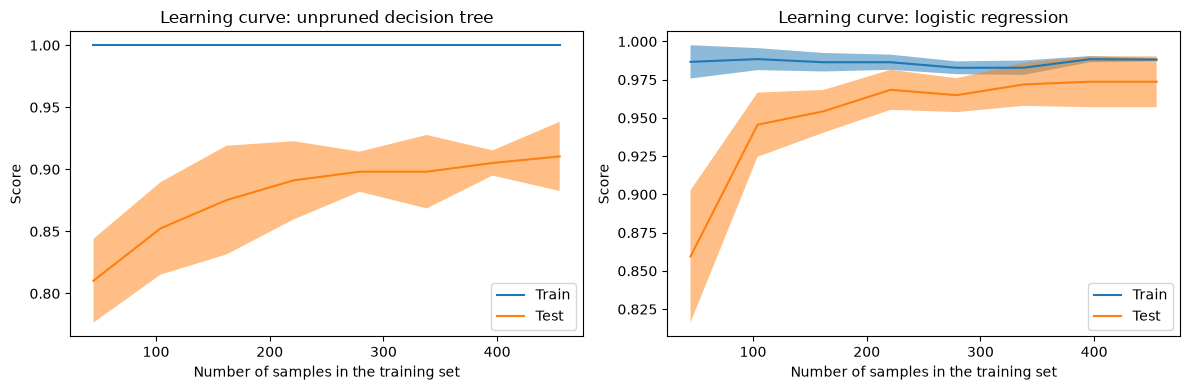

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
LearningCurveDisplay.from_estimator(DecisionTreeClassifier(random_state=42), X, y, cv=cv,
                                    train_sizes=np.linspace(0.1, 1.0, 8), ax=axes[0])
axes[0].set_title('Learning curve: unpruned decision tree')
LearningCurveDisplay.from_estimator(model, X, y, cv=cv,
                                    train_sizes=np.linspace(0.1, 1.0, 8), ax=axes[1])
axes[1].set_title('Learning curve: logistic regression')
plt.tight_layout()
plt.show()

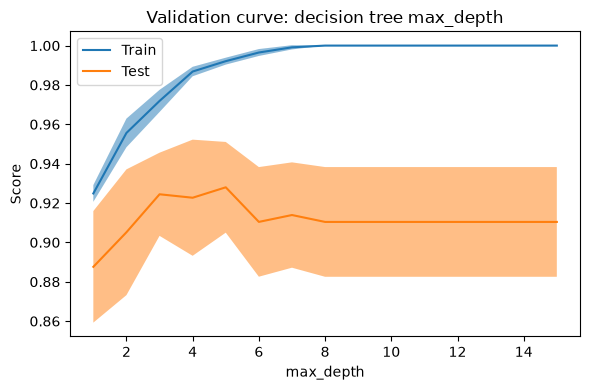

In [14]:
fig, ax = plt.subplots(figsize=(6, 4))
ValidationCurveDisplay.from_estimator(
    DecisionTreeClassifier(random_state=42), X, y, param_name='max_depth',
    param_range=np.arange(1, 16), cv=cv, ax=ax)
ax.set_title('Validation curve: decision tree max_depth')
plt.tight_layout()
plt.show()

The unpruned decision tree has a perfect training score and a clearly lower validation score, a sign of overfitting. Logistic regression keeps the two curves close together. In the validation curve, very shallow trees underfit (both scores lower), validation accuracy peaks at a moderate depth, and deeper trees only increase the gap between training and validation scores.

## Chapter Summary

- A single **holdout** split gives an unstable estimate; **cross-validation** uses every sample for testing and reports both the mean and the spread.
- **StratifiedKFold** keeps class proportions in each fold; **GroupKFold** keeps related samples together; **TimeSeriesSplit** respects time order.
- `cross_validate` computes several metrics plus training scores, and `cross_val_predict` gives out-of-fold predictions for honest error analysis.
- Metrics should match the problem; scorers follow "higher is better", and custom metrics are created with `make_scorer`.
- **Dummy models** provide the baseline every real model must beat.
- **GridSearchCV**, **RandomizedSearchCV**, and **HalvingGridSearchCV** tune hyperparameters with different cost-thoroughness trade-offs.
- **Nested cross-validation** gives an unbiased estimate of a model that includes hyperparameter tuning.
- **Learning curves** and **validation curves** diagnose overfitting and underfitting and guide the next step.